# Solución de la ecuación de ondas 2D mediante PINNs

## Parte analítica y formulación del problema

Consideremos una membrana cuadrada de lado unitario, con bordes fijos, cuyos desplazamientos transversales $U(x,y,t)$ respecto a su posición de equilibrio están descritos, en el régimen de pequeñas oscilaciones, por la ecuación de ondas adimensional:

$$
\frac{\partial^2 U}{\partial t^2} = \frac{\partial^2 U}{\partial x^2} + \frac{\partial^2 U}{\partial y^2},
$$

con $U = 0$ en los bordes y condiciones iniciales:

$$
U(x, y, 0) = \sin(\pi x)\sin(\pi y),
$$
$$
U_t(x, y, 0) = \sqrt{2}\pi \sin(\pi x)\sin(\pi y).
$$

Se aproxima el desplazamiento $U(x,y,t)$ mediante una PINN de la forma:

$$
U_\theta(x, y, t) = \sin(\pi x)\sin(\pi y)a_\theta(t),
$$

donde $a_\theta(t)$ se representa mediante las arquitecturas **Modelo A** (una capa con dos neuronas de activación sinusoidal) y **Modelo B** (dos capas consecutivas, con una neurona por capa).

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

np.random.seed(42)
tf.random.set_seed(42)

# Precisión numérica para las derivadas
DTYPE = tf.float64
tf.keras.backend.set_floatx("float64")

print("TensorFlow:", tf.__version__)
print("Entorno preparado correctamente.")

TensorFlow: 2.21.0
Entorno preparado correctamente.


## Reducción a una ecuación diferencial ordinaria

Al sustituir la forma propuesta para $U_\theta$ en la ecuación de ondas, obtenemos:

$$
\sin(\pi x)\sin(\pi y) [a_\theta''(t) + 2\pi^2 a_\theta(t)] = 0.
$$

En el interior del dominio, $\sin(\pi x)\sin(\pi y) \neq 0$, por lo que la ecuación en derivadas parciales se reduce a la ecuación diferencial ordinaria:

$$
a_\theta''(t) + 2\pi^2 a_\theta(t) = 0.
$$

Las condiciones iniciales exigen que $a_\theta(0) = 1$ y $a_\theta'(0) = \sqrt{2}\pi$. La solución analítica exacta para la amplitud es:

$$
a_{\text{exacta}}(t) = \cos(\omega_0 t) + \sin(\omega_0 t),
\qquad \omega_0 = \sqrt{2}\pi.
$$

In [48]:
# Parámetros físicos
omega_0 = np.sqrt(2.0) * np.pi
T = 3.0

N_f = 300
t_f_np = np.linspace(0.0, T, N_f).reshape(-1, 1)

t_f = tf.constant(t_f_np, dtype=DTYPE)

def a_exact(t):
    return np.cos(omega_0 * t) + np.sin(omega_0 * t)

def U_exact(x, y, t):
    return np.sin(np.pi * x) * np.sin(np.pi * y) * a_exact(t)

print("Frecuencia angular:", omega_0)
print("Número de puntos de colocación:", N_f)

Frecuencia angular: 4.442882938158366
Número de puntos de colocación: 300


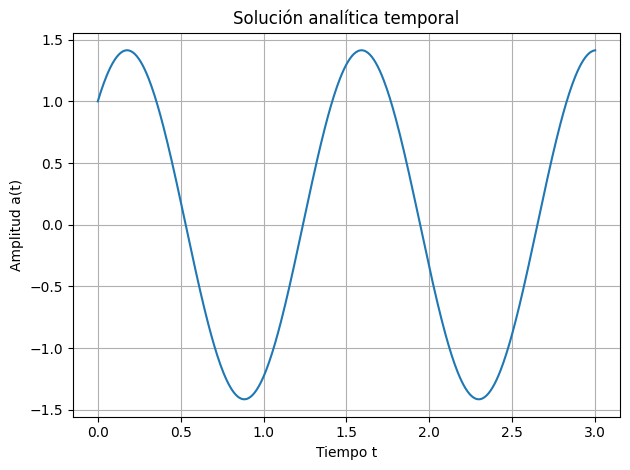

In [49]:
t_plot = np.linspace(0.0, T, 500)
a_plot = a_exact(t_plot)

plt.plot(t_plot, a_plot)
plt.xlabel("Tiempo t")
plt.ylabel("Amplitud a(t)")
plt.title("Solución analítica temporal")
plt.grid(True)


plt.tight_layout()
plt.show()

## Arquitecturas de las Redes Neuronales (PINNs)

### Modelo A
Una capa con dos neuronas de activación sinusoidal:
$$
a_A(t) = \sum_{j=1}^{2} A_j \sin(w_j t + b_j).
$$

### Modelo B
Dos capas consecutivas, con una neurona por capa:
$$
h_1(t) = \sin(w_1 t + b_1),
$$
$$
a_B(t) = A \sin(w_2 h_1(t) + b_2).
$$

In [50]:
class ModeloA(keras.Model):
    def __init__(self):
        super().__init__(dtype=DTYPE)

        self.A = self.add_weight(
            name="amplitudes",
            shape=(2,),
            initializer=keras.initializers.Constant([1.0, 0.1]),
            dtype=DTYPE
        )

        self.w = self.add_weight(
            name="frecuencias",
            shape=(2,),
            initializer=keras.initializers.Constant(
                [omega_0, 0.8 * omega_0]
            ),
            dtype=DTYPE
        )

        self.b = self.add_weight(
            name="fases",
            shape=(2,),
            initializer=keras.initializers.Constant(
                [np.pi / 4, 0.0]
            ),
            dtype=DTYPE
        )

    def call(self, t):
        z = t * self.w[None, :] + self.b[None, :]
        return tf.reduce_sum(
            self.A[None, :] * tf.sin(z),
            axis=1,
            keepdims=True
        )

In [51]:
class ModeloB(keras.Model):
    def __init__(self):
        super().__init__(dtype=DTYPE)

        self.A = self.add_weight(
            name="amplitud",
            shape=(),
            initializer=keras.initializers.Constant(1.0),
            dtype=DTYPE
        )

        self.w1 = self.add_weight(
            name="frecuencia_1",
            shape=(),
            initializer=keras.initializers.Constant(1.0),
            dtype=DTYPE
        )

        self.b1 = self.add_weight(
            name="fase_1",
            shape=(),
            initializer=keras.initializers.Constant(0.0),
            dtype=DTYPE
        )

        self.w2 = self.add_weight(
            name="frecuencia_2",
            shape=(),
            initializer=keras.initializers.Constant(0.5),
            dtype=DTYPE
        )

        self.b2 = self.add_weight(
            name="fase_2",
            shape=(),
            initializer=keras.initializers.Constant(0.5),
            dtype=DTYPE
        )

    def call(self, t):
        h1 = tf.sin(self.w1 * t + self.b1)
        return self.A * tf.sin(self.w2 * h1 + self.b2)

In [52]:
modelo_A = ModeloA()
modelo_B = ModeloB()

a_A = modelo_A(t_f)
a_B = modelo_B(t_f)

print("Modelo A:", a_A.shape)
print("Modelo B:", a_B.shape)

print("\nParámetros del Modelo A:")
for variable in modelo_A.trainable_variables:
    print(variable.name, variable.numpy())

print("\nParámetros del Modelo B:")
for variable in modelo_B.trainable_variables:
    print(variable.name, variable.numpy())

Modelo A: (300, 1)
Modelo B: (300, 1)

Parámetros del Modelo A:
amplitudes [1.  0.1]
frecuencias [4.44288294 3.55430635]
fases [0.78539819 0.        ]

Parámetros del Modelo B:
amplitud 1.0
frecuencia_1 1.0
fase_1 0.0
frecuencia_2 0.5
fase_2 0.5


## Entrenamiento 1: Función de pérdida sin ligadura (Solo PDE + CI)

Construimos una función de coste que incorpora únicamente el residuo de la ecuación diferencial y las condiciones iniciales:
$$
J(\theta) = J_{\text{PDE}} + J_{\text{CI}}.
$$

In [53]:
def derivadas(modelo, t):
    with tf.GradientTape() as tape2:
        tape2.watch(t)
        with tf.GradientTape() as tape1:
            tape1.watch(t)
            a = modelo(t)
        da = tape1.gradient(a, t)
    d2a = tape2.gradient(da, t)
    return a, da, d2a

In [54]:
def calcular_perdidas_basica(modelo, t_f):
    a, da, d2a = derivadas(modelo, t_f)
    residuo = d2a + 2.0 * np.pi**2 * a
    perdida_fisica = tf.reduce_mean(tf.square(residuo))

    t0 = tf.constant([[0.0]], dtype=DTYPE)
    a0_pred, da0_pred, _ = derivadas(modelo, t0)
    perdida_inicial = (
        tf.square(a0_pred[0, 0] - 1.0)
        + tf.square(da0_pred[0, 0] - np.sqrt(2.0) * np.pi)
    )

    perdida_total = perdida_fisica + perdida_inicial
    return perdida_total, perdida_fisica, perdida_inicial

In [55]:
def entrenar_modelo_basico(modelo, t_f, epochs=3000, learning_rate=1e-3):
    optimizador = keras.optimizers.Adam(learning_rate=learning_rate)
    historial = []

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            perdida, p_fisica, p_inicial = calcular_perdidas_basica(modelo, t_f)

        gradientes = tape.gradient(perdida, modelo.trainable_variables)
        optimizador.apply_gradients(zip(gradientes, modelo.trainable_variables))

        historial.append([perdida.numpy(), p_fisica.numpy(), p_inicial.numpy()])

        if epoch % 1000 == 0:
            print(
                f"Época {epoch:5d} | Total: {perdida.numpy():.3e} | "
                f"PDE: {p_fisica.numpy():.3e} | CI: {p_inicial.numpy():.3e}"
            )
    return np.array(historial)

In [56]:
modelo_A_basico = ModeloA()
modelo_B_basico = ModeloB()

print("Entrenando Modelo A (Sin Energía)...")
historial_A_basico = entrenar_modelo_basico(modelo_A_basico, t_f)

print("\nEntrenando Modelo B (Sin Energía)...")
historial_B_basico = entrenar_modelo_basico(modelo_B_basico, t_f)

Entrenando Modelo A (Sin Energía)...
Época     0 | Total: 1.226e+00 | PDE: 2.451e-01 | CI: 9.804e-01
Época  1000 | Total: 1.016e-02 | PDE: 2.160e-04 | CI: 9.948e-03
Época  2000 | Total: 2.461e-05 | PDE: 5.701e-07 | CI: 2.404e-05

Entrenando Modelo B (Sin Energía)...
Época     0 | Total: 2.202e+02 | PDE: 2.039e+02 | CI: 1.630e+01
Época  1000 | Total: 2.082e+01 | PDE: 6.775e-01 | CI: 2.014e+01
Época  2000 | Total: 2.046e+01 | PDE: 2.269e-01 | CI: 2.023e+01


## Entrenamiento 2: Función de pérdida con ligadura de energía

El problema sugiere que la energía mecánica total se conserva. Para la forma de nuestra solución, la energía es:
$$
E(t) = \frac{1}{8}[a_\theta'(t)]^2 + \frac{\pi^2}{4}[a_\theta(t)]^2.
$$

Añadimos la pérdida de conservación de energía $J_E = \frac{1}{N_f} \sum [E(t_i) - E(0)]^2$ a la función de coste:
$$
J(\theta) = J_{\text{PDE}} + J_{\text{CI}} + \lambda_E J_E.
$$

In [57]:
def energia(modelo, t):
    a, da, _ = derivadas(modelo, t)
    E = (1.0 / 8.0) * tf.square(da) + (np.pi**2 / 4.0) * tf.square(a)
    return E

def calcular_perdidas_con_energia(modelo, t_f, lambda_E=1.0):
    a, da, d2a = derivadas(modelo, t_f)
    residuo = d2a + 2.0 * np.pi**2 * a
    perdida_fisica = tf.reduce_mean(tf.square(residuo))

    t0 = tf.constant([[0.0]], dtype=DTYPE)
    a0_pred, da0_pred, _ = derivadas(modelo, t0)
    perdida_inicial = (
        tf.square(a0_pred[0, 0] - 1.0)
        + tf.square(da0_pred[0, 0] - np.sqrt(2.0) * np.pi)
    )

    E_t = energia(modelo, t_f)
    E_0 = energia(modelo, t0)
    perdida_energia = tf.reduce_mean(tf.square(E_t - E_0))

    perdida_total = perdida_fisica + perdida_inicial + lambda_E * perdida_energia
    return perdida_total, perdida_fisica, perdida_inicial, perdida_energia

In [58]:
def entrenar_modelo_con_energia(modelo, t_f, epochs=3000, learning_rate=1e-3, lambda_E=1.0):
    optimizador = keras.optimizers.Adam(learning_rate=learning_rate)
    historial = []

    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            perdida, p_fisica, p_inicial, p_energia = calcular_perdidas_con_energia(
                modelo, t_f, lambda_E=lambda_E
            )

        gradientes = tape.gradient(perdida, modelo.trainable_variables)
        optimizador.apply_gradients(zip(gradientes, modelo.trainable_variables))

        historial.append([perdida.numpy(), p_fisica.numpy(), p_inicial.numpy(), p_energia.numpy()])

        if epoch % 1000 == 0:
            print(
                f"Época {epoch:5d} | Total: {perdida.numpy():.3e} | "
                f"PDE: {p_fisica.numpy():.3e} | CI: {p_inicial.numpy():.3e} | "
                f"Energía: {p_energia.numpy():.3e}"
            )
    return np.array(historial)

In [59]:
modelo_A_energy = ModeloA()
modelo_B_energy = ModeloB()

print("Entrenando Modelo A (Con Energía)...")
historial_A_energy = entrenar_modelo_con_energia(modelo_A_energy, t_f, lambda_E=1.0)

print("\nEntrenando Modelo B (Con Energía)...")
historial_B_energy = entrenar_modelo_con_energia(modelo_B_energy, t_f, lambda_E=1.0)

Entrenando Modelo A (Con Energía)...
Época     0 | Total: 1.485e+00 | PDE: 2.451e-01 | CI: 9.804e-01 | Energía: 2.592e-01
Época  1000 | Total: 1.372e-02 | PDE: 1.323e-05 | CI: 1.368e-02 | Energía: 2.542e-05
Época  2000 | Total: 6.981e-05 | PDE: 6.495e-08 | CI: 6.961e-05 | Energía: 1.396e-07

Entrenando Modelo B (Con Energía)...
Época     0 | Total: 2.209e+02 | PDE: 2.039e+02 | CI: 1.630e+01 | Energía: 6.948e-01
Época  1000 | Total: 2.084e+01 | PDE: 6.990e-01 | CI: 2.015e+01 | Energía: 1.636e-05
Época  2000 | Total: 2.048e+01 | PDE: 2.186e-01 | CI: 2.026e+01 | Energía: 3.931e-06


## Comparación directa: Modelo sin energía vs. Modelo con energía

Evaluamos las 4 predicciones (A y B, con y sin energía) y las comparamos visualmente con la solución exacta.

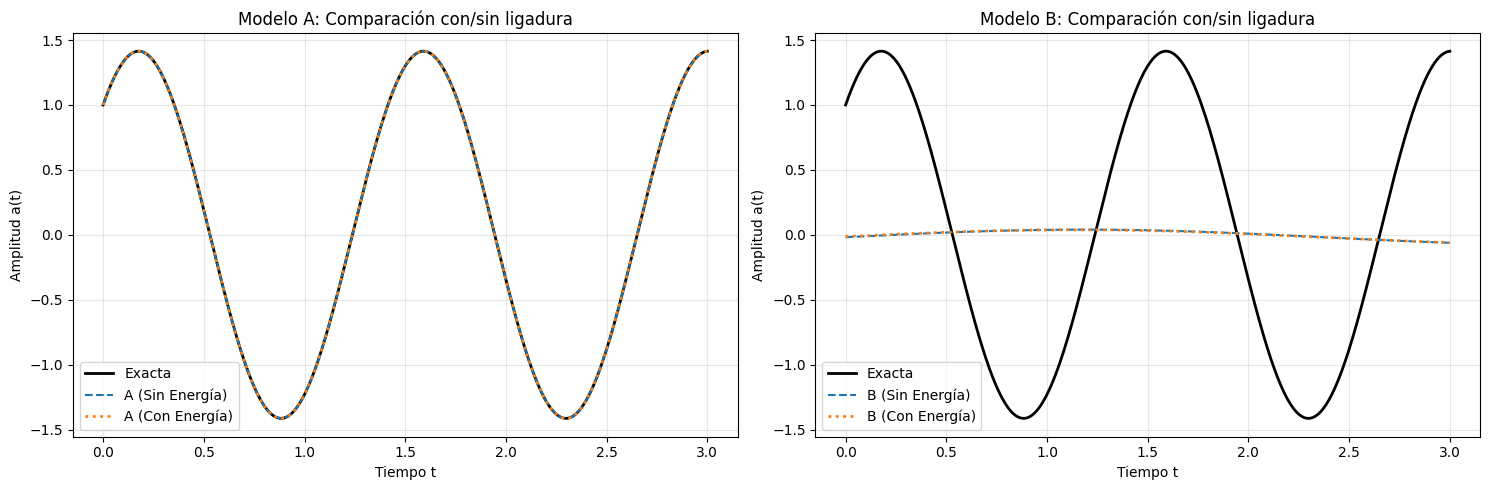

In [60]:
t_eval_np = np.linspace(0.0, T, 1000)
t_eval = tf.constant(t_eval_np.reshape(-1, 1), dtype=DTYPE)

a_ref = a_exact(t_eval_np)

a_pred_A_basico = modelo_A_basico(t_eval).numpy().flatten()
a_pred_B_basico = modelo_B_basico(t_eval).numpy().flatten()
a_pred_A_energy = modelo_A_energy(t_eval).numpy().flatten()
a_pred_B_energy = modelo_B_energy(t_eval).numpy().flatten()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(t_eval_np, a_ref, "k-", linewidth=2, label="Exacta")
axes[0].plot(t_eval_np, a_pred_A_basico, "--", label="A (Sin Energía)")
axes[0].plot(t_eval_np, a_pred_A_energy, ":", linewidth=2, label="A (Con Energía)")
axes[0].set_title("Modelo A: Comparación con/sin ligadura")
axes[0].set_xlabel("Tiempo t")
axes[0].set_ylabel("Amplitud a(t)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, a_ref, "k-", linewidth=2, label="Exacta")
axes[1].plot(t_eval_np, a_pred_B_basico, "--", label="B (Sin Energía)")
axes[1].plot(t_eval_np, a_pred_B_energy, ":", linewidth=2, label="B (Con Energía)")
axes[1].set_title("Modelo B: Comparación con/sin ligadura")
axes[1].set_xlabel("Tiempo t")
axes[1].set_ylabel("Amplitud a(t)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [61]:
def calcular_metricas(prediccion, referencia):
    return {
        "MAE": mean_absolute_error(referencia, prediccion),
        "RMSE": np.sqrt(mean_squared_error(referencia, prediccion)),
        "Error máximo": np.max(np.abs(prediccion - referencia))
    }

metricas_A_base = calcular_metricas(a_pred_A_basico, a_ref)
metricas_A_energ = calcular_metricas(a_pred_A_energy, a_ref)
metricas_B_base = calcular_metricas(a_pred_B_basico, a_ref)
metricas_B_energ = calcular_metricas(a_pred_B_energy, a_ref)

df_comparacion = pd.DataFrame({
    "Modelo A (Sin Energía)": metricas_A_base,
    "Modelo A (Con Energía)": metricas_A_energ,
    "Modelo B (Sin Energía)": metricas_B_base,
    "Modelo B (Con Energía)": metricas_B_energ
})

display(df_comparacion)

,Modelo A (Sin Energía),Modelo A (Con Energía),Modelo B (Sin Energía),Modelo B (Con Energía)
MAE,0.000013,0.000044,0.925401,0.924852
RMSE,0.000015,0.000049,1.022403,1.021747
Error máximo,0.000021,0.000068,1.475414,1.473498


## Análisis de la conservación de energía

Comparamos cómo evoluciona la energía mecánica total en los modelos entrenados sin la ligadura vs. los entrenados con la ligadura. La energía teórica esperada es $E_{\text{teórica}} = \frac{\pi^2}{2}$.

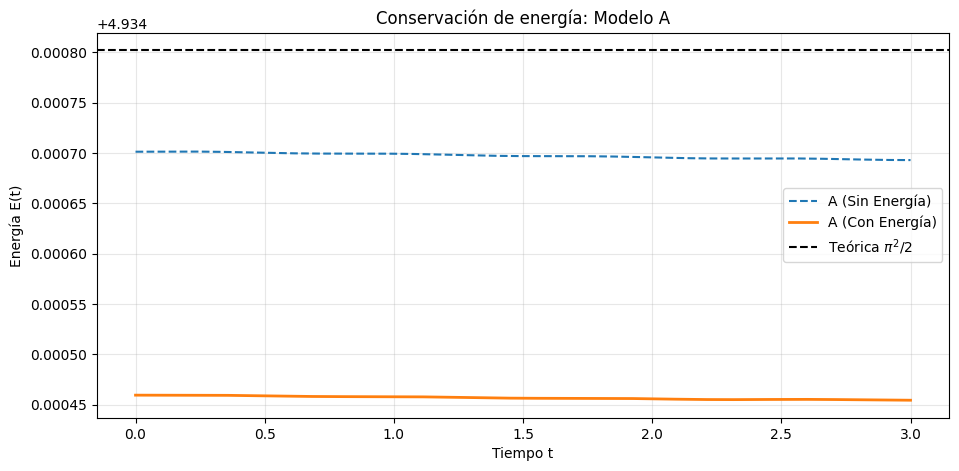

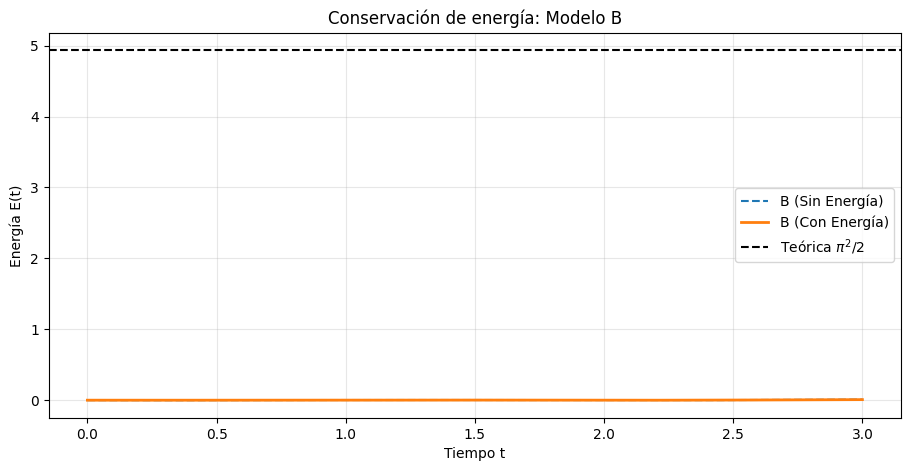

In [62]:
E_teorica = np.pi**2 / 2.0
E_A_base = energia(modelo_A_basico, t_eval).numpy().flatten()
E_A_energ = energia(modelo_A_energy, t_eval).numpy().flatten()
E_B_base = energia(modelo_B_basico, t_eval).numpy().flatten()
E_B_energ = energia(modelo_B_energy, t_eval).numpy().flatten()

plt.figure(figsize=(11, 5))
plt.plot(t_eval_np, E_A_base, "--", label="A (Sin Energía)")
plt.plot(t_eval_np, E_A_energ, "-", linewidth=2, label="A (Con Energía)")
plt.axhline(E_teorica, color="black", linestyle="--", label=r"Teórica $\pi^2/2$")
plt.title("Conservación de energía: Modelo A")
plt.xlabel("Tiempo t")
plt.ylabel("Energía E(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(t_eval_np, E_B_base, "--", label="B (Sin Energía)")
plt.plot(t_eval_np, E_B_energ, "-", linewidth=2, label="B (Con Energía)")
plt.axhline(E_teorica, color="black", linestyle="--", label=r"Teórica $\pi^2/2$")
plt.title("Conservación de energía: Modelo B")
plt.xlabel("Tiempo t")
plt.ylabel("Energía E(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

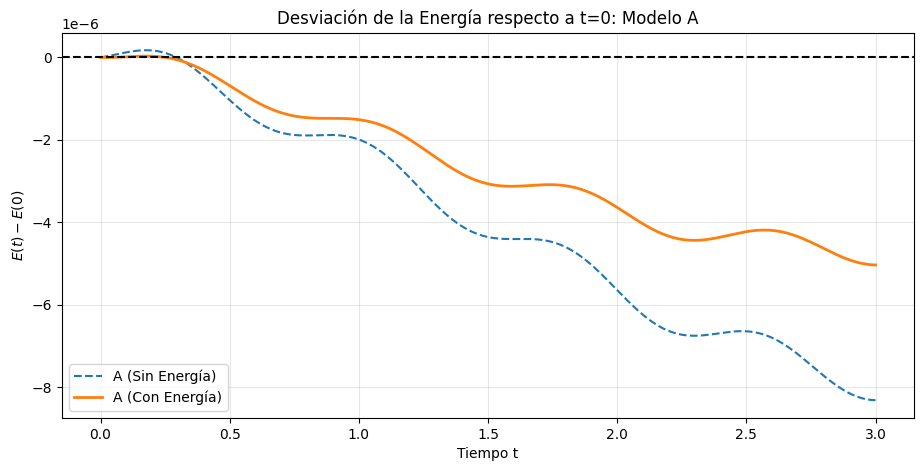

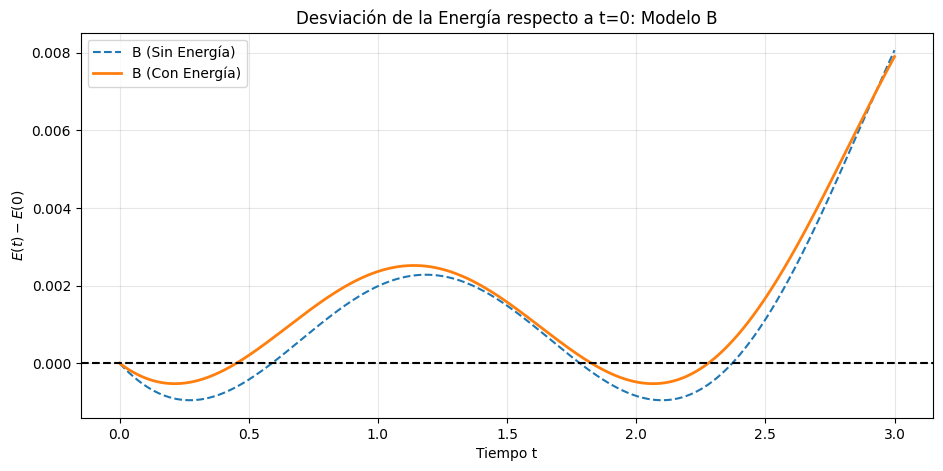

In [63]:
delta_E_A_base = E_A_base - E_A_base[0]
delta_E_A_energ = E_A_energ - E_A_energ[0]
delta_E_B_base = E_B_base - E_B_base[0]
delta_E_B_energ = E_B_energ - E_B_energ[0]

plt.figure(figsize=(11, 5))
plt.plot(t_eval_np, delta_E_A_base, "--", label="A (Sin Energía)")
plt.plot(t_eval_np, delta_E_A_energ, "-", linewidth=2, label="A (Con Energía)")
plt.axhline(0, color="black", linestyle="--")
plt.title("Desviación de la Energía respecto a t=0: Modelo A")
plt.xlabel("Tiempo t")
plt.ylabel(r"$E(t)-E(0)$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(t_eval_np, delta_E_B_base, "--", label="B (Sin Energía)")
plt.plot(t_eval_np, delta_E_B_energ, "-", linewidth=2, label="B (Con Energía)")
plt.axhline(0, color="black", linestyle="--")
plt.title("Desviación de la Energía respecto a t=0: Modelo B")
plt.xlabel("Tiempo t")
plt.ylabel(r"$E(t)-E(0)$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Conclusión

De la comparación directa se extraen las siguientes conclusiones:

1. **Capacidad de representación:** El Modelo A tiene intrínsecamente la capacidad de aproximar perfectamente la solución exacta (suma de senos). Sin embargo, al no incluir la restricción de energía, puede desviarse ligeramente con el tiempo o ajustar los parámetros a un mínimo local.
2. **Efecto de la ligadura:** Al añadir el término de energía, forzamos a la red a encontrar parámetros que no solo minimicen el residuo de la PDE, sino que respeten la física global del sistema. En el Modelo A, se observa que la energía con ligadura se mantiene mucho más cercana al valor teórico constante.
3. **Modelo B:** Al tener una arquitectura más limitada para representar esta dinámica específica, el Modelo B sin energía presenta errores y fluctuaciones de energía mayores. La ligadura ayuda a estabilizar su comportamiento, aunque su error de aproximación sigue siendo mayor que el del Modelo A.
4. **Metodología PINN:** Se demuestra que la inclusión de leyes de conservación (como la energía) como términos de penalización (soft constraints) en la función de pérdida mejora significativamente la fidelidad física y estabilidad de los modelos neuronales.

In [64]:
E_exacta = np.pi**2 / 2.0

resumen = {
    "Modelo": ["A (Sin E)", "A (Con E)", "B (Sin E)", "B (Con E)"],
    "MAE": [metricas_A_base["MAE"], metricas_A_energ["MAE"], metricas_B_base["MAE"], metricas_B_energ["MAE"]],
    "RMSE": [metricas_A_base["RMSE"], metricas_A_energ["RMSE"], metricas_B_base["RMSE"], metricas_B_energ["RMSE"]],
    "Desv. Energía Máx": [
        np.max(np.abs(delta_E_A_base)),
        np.max(np.abs(delta_E_A_energ)),
        np.max(np.abs(delta_E_B_base)),
        np.max(np.abs(delta_E_B_energ))
    ],
    "Error Energético Relativo": [
        np.max(np.abs(E_A_base - E_exacta)) / E_exacta,
        np.max(np.abs(E_A_energ - E_exacta)) / E_exacta,
        np.max(np.abs(E_B_base - E_exacta)) / E_exacta,
        np.max(np.abs(E_B_energ - E_exacta)) / E_exacta
    ]
}

tabla_final = pd.DataFrame(resumen)
display(tabla_final)

,Modelo,MAE,RMSE,Desv. Energía Máx,Error Energético Relativo
0,A (Sin E),0.000013,0.000015,0.000008,0.000022
1,A (Con E),0.000044,0.000049,0.000005,0.000070
2,B (Sin E),0.925401,1.022403,0.008061,0.999865
3,B (Con E),0.924852,1.021747,0.007898,0.999877
